**<h2> MBTI-Predicción de Personalidad con Machine Learning </h2>**
<hr>

Alumnos :<br>
Ronald Portocarrero<br>
Dylan Nuñez<br>
Universidad Nacional de Ingeniería


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
import numpy as np
import nltk
import re
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_extraction.text import CountVectorizer,TfidfTransformer
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GridSearchCV

In [ ]:
mbti_df=pd.read_csv('/content/drive/MyDrive/Colab Notebooks/mbti_1.csv')

In [ ]:
mbti_df.head()

,type,posts
0,INFJ,'http://www.youtube.com/watch?v=qsXHcwe3krw|||...
1,ENTP,'I'm finding the lack of me in these posts ver...
2,INTP,'Good one _____ https://www.youtube.com/wat...
3,INTJ,"'Dear INTP, I enjoyed our conversation the o..."
4,ENTJ,'You're fired.|||That's another silly misconce...


In [ ]:
mbti_df.posts[0]

"'http://www.youtube.com/watch?v=qsXHcwe3krw|||http://41.media.tumblr.com/tumblr_lfouy03PMA1qa1rooo1_500.jpg|||enfp and intj moments  https://www.youtube.com/watch?v=iz7lE1g4XM4  sportscenter not top ten plays  https://www.youtube.com/watch?v=uCdfze1etec  pranks|||What has been the most life-changing experience in your life?|||http://www.youtube.com/watch?v=vXZeYwwRDw8   http://www.youtube.com/watch?v=u8ejam5DP3E  On repeat for most of today.|||May the PerC Experience immerse you.|||The last thing my INFJ friend posted on his facebook before committing suicide the next day. Rest in peace~   http://vimeo.com/22842206|||Hello ENFJ7. Sorry to hear of your distress. It's only natural for a relationship to not be perfection all the time in every moment of existence. Try to figure the hard times as times of growth, as...|||84389  84390  http://wallpaperpassion.com/upload/23700/friendship-boy-and-girl-wallpaper.jpg  http://assets.dornob.com/wp-content/uploads/2010/04/round-home-design.jpg ...

In [ ]:
mbti_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8675 entries, 0 to 8674
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   type    8675 non-null   object
 1   posts   8675 non-null   object
dtypes: object(2)
memory usage: 135.7+ KB


##Visualización de Datos

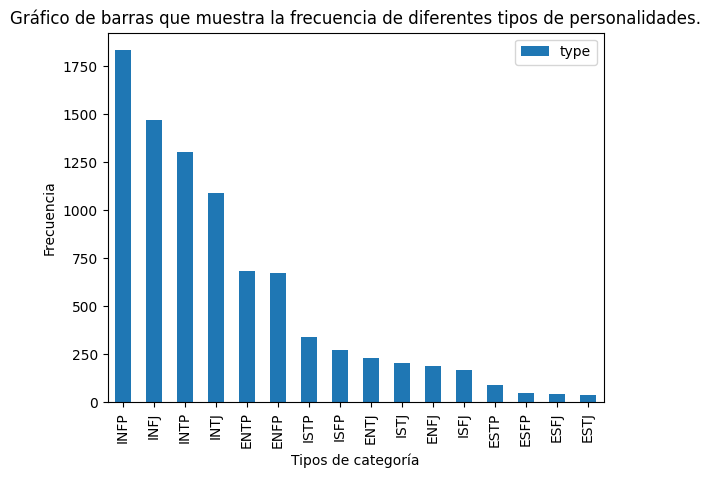

In [ ]:
pd.DataFrame(mbti_df.type.value_counts()).plot.bar()
plt.ylabel('Frecuencia')
plt.xlabel('Tipos de categoría')
plt.title('Gráfico de barras que muestra la frecuencia de diferentes tipos de personalidades.')
plt.show()

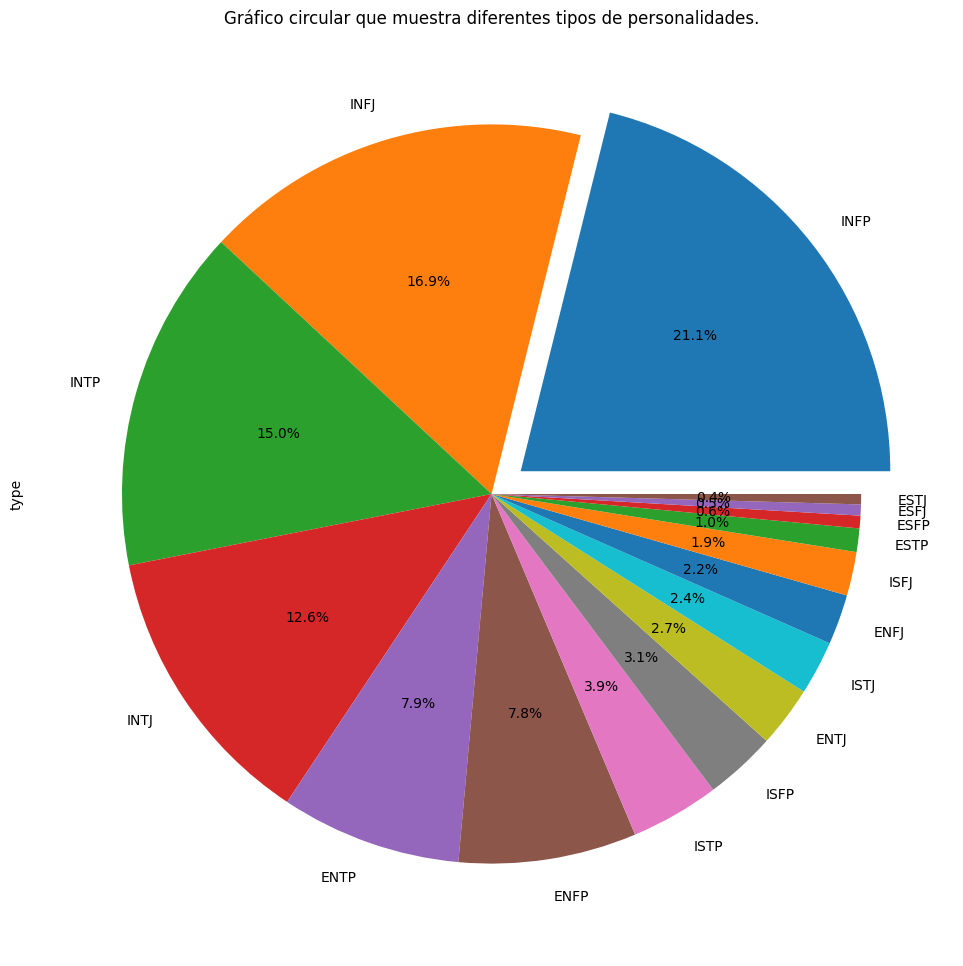

In [ ]:
mbti_df.type.value_counts().plot(kind='pie',figsize=(12,12), autopct='%1.1f%%', explode=[0.1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0])
plt.title('Gráfico circular que muestra diferentes tipos de personalidades.')
plt.show()

<ipython-input-10-ecd7ce8062e0>:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(mbti_df["posts"].apply(len))


Text(0.5, 1.0, 'Distribución de longitudes de la publicación.')

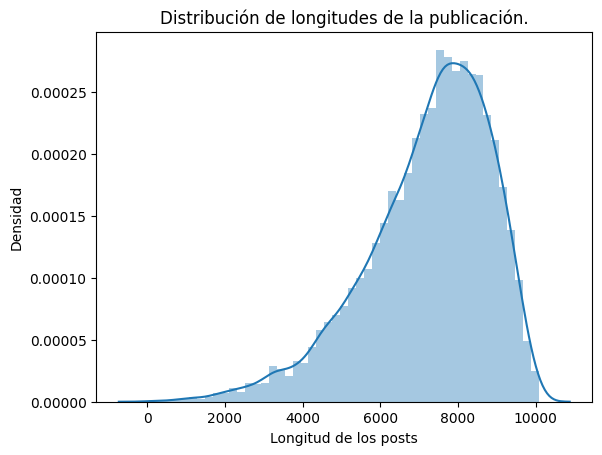

In [ ]:
sns.distplot(mbti_df["posts"].apply(len))
plt.xlabel("Longitud de los posts")
plt.ylabel("Densidad")
plt.title("Distribución de longitudes de la publicación.")

Vemos la cantidad de palabras:

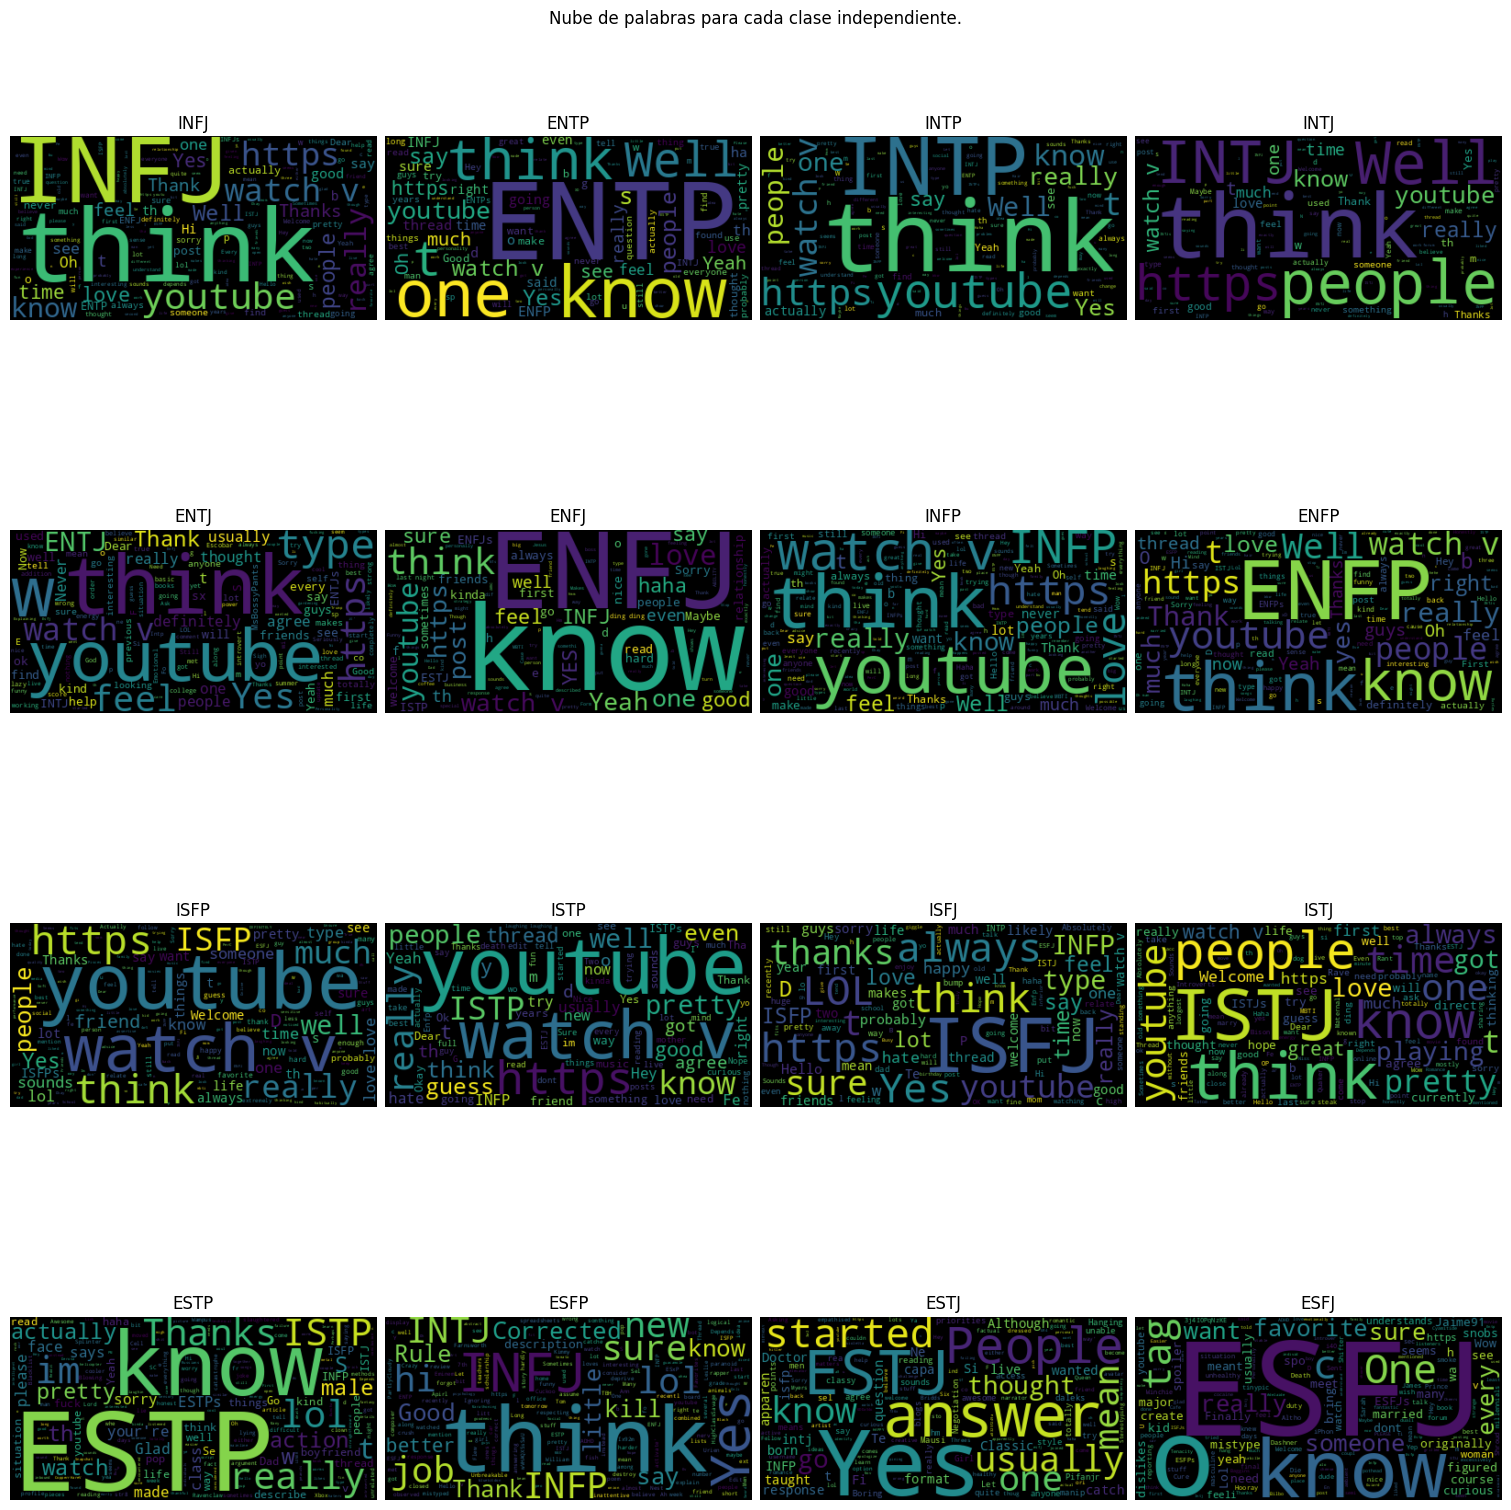

In [ ]:
import matplotlib.pyplot as plt
from wordcloud import WordCloud
num_classes = len(mbti_df['type'].unique())
num_rows = num_classes // 4 + (1 if num_classes % 4 != 0 else 0)
num_cols = min(4, num_classes)

fig, axs = plt.subplots(num_rows, num_cols, figsize=(15, 4 * num_rows), constrained_layout=True)
plt.suptitle("Nube de palabras para cada clase independiente.")

if not isinstance(axs, np.ndarray):
    axs = np.array([axs])

for i, ax in zip(mbti_df['type'].unique(), axs.flat):
    df_4 = mbti_df[mbti_df['type'] == i]
    wordcloud = WordCloud(max_words=1628, relative_scaling=1, normalize_plurals=False).generate(df_4['posts'].to_string())
    ax.imshow(wordcloud, interpolation='bilinear')
    ax.set_title(i)
    ax.axis("off")

for ax in axs.flat[num_classes:]:
    ax.set_visible(False)

plt.show()

Limpiamos los datos:

In [ ]:
from nltk.corpus import wordnet
wordnet.synsets("hello")

[Synset('hello.n.01')]

In [ ]:
import nltk
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [ ]:
def clear_text(df):
    data_length=[]
    lemmatizer=WordNetLemmatizer()
    cleaned_text=[]
    stop_words = set(stopwords.words('english')) # Load stop words
    pers_types = ['INFP' ,'INFJ', 'INTP', 'INTJ', 'ENTP', 'ENFP', 'ISTP' ,'ISFP' ,'ENTJ', 'ISTJ','ENFJ', 'ISFJ' ,'ESTP', 'ESFP' ,'ESFJ' ,'ESTJ']
    pers_types = [p.lower() for p in pers_types]

    print("Cleaning The Dataset")
    for sentence in tqdm(df.posts):

        sentence=sentence.lower()

        sentence=re.sub('https?://[^\s<>"]+|www\.[^\s<>"]+',' ',sentence)

        sentence=re.sub('[^0-9a-z]',' ',sentence)

        sentence = " ".join([word for word in sentence.split() if word not in stop_words]) # Remove stop words
        #print(len(sentence))

        for p in pers_types:
            sentence = re.sub(p, '', sentence)
        #print(len(sentence))

        sentence = lemmatizer.lemmatize(sentence) # Lemmatize words

        data_length.append(len(sentence.split())) #Split data, measure length of new filtered data

        cleaned_text.append(sentence)

    return cleaned_text,data_length

In [ ]:
nltk.data.path

['/root/nltk_data',
 '/usr/nltk_data',
 '/usr/share/nltk_data',
 '/usr/lib/nltk_data',
 '/usr/share/nltk_data',
 '/usr/local/share/nltk_data',
 '/usr/lib/nltk_data',
 '/usr/local/lib/nltk_data']

In [ ]:
from nltk.stem import *

In [ ]:
from nltk.corpus import *
from tqdm import tqdm

In [ ]:
df_clean = mbti_df
df_clean.posts,df_clean_length=clear_text(mbti_df)
df_clean

Cleaning The Dataset


100%|██████████| 8675/8675 [00:08<00:00, 1043.06it/s]


,type,posts
0,INFJ,moments sportscenter top ten plays pranks lif...
1,ENTP,finding lack posts alarming sex boring positio...
2,INTP,good one course say know blessing curse absolu...
3,INTJ,dear enjoyed conversation day esoteric gabbin...
4,ENTJ,fired another silly misconception approaching ...
...,...,...
8670,ISFP,always think cats fi doms reason websites beco...
8671,ENFP,thread already exists someplace else heck dele...
8672,INTP,many questions things would take purple pill p...
8673,INFP,conflicted right comes wanting children honest...


In [ ]:
df_clean.posts[0]

' moments sportscenter top ten plays pranks life changing experience life repeat today may perc experience immerse last thing  friend posted facebook committing suicide next day rest peace 7 sorry hear distress natural relationship perfection time every moment existence try figure hard times times growth 84389 84390 welcome stuff game set match prozac wellbrutin least thirty minutes moving legs mean moving sitting desk chair weed moderation maybe try edibles healthier alternative basically come three items determined type whichever types want would likely use given types cognitive functions whatnot left things moderation sims indeed video game good one note good one somewhat subjective completely promoting death given sim dear  favorite video games growing current favorite video games cool appears late sad someone everyone wait thought confidence good thing cherish time solitude b c revel within inner world whereas time workin enjoy time worry people always around yo  ladies compliment

In [ ]:
len(df_clean.posts[0])

2035

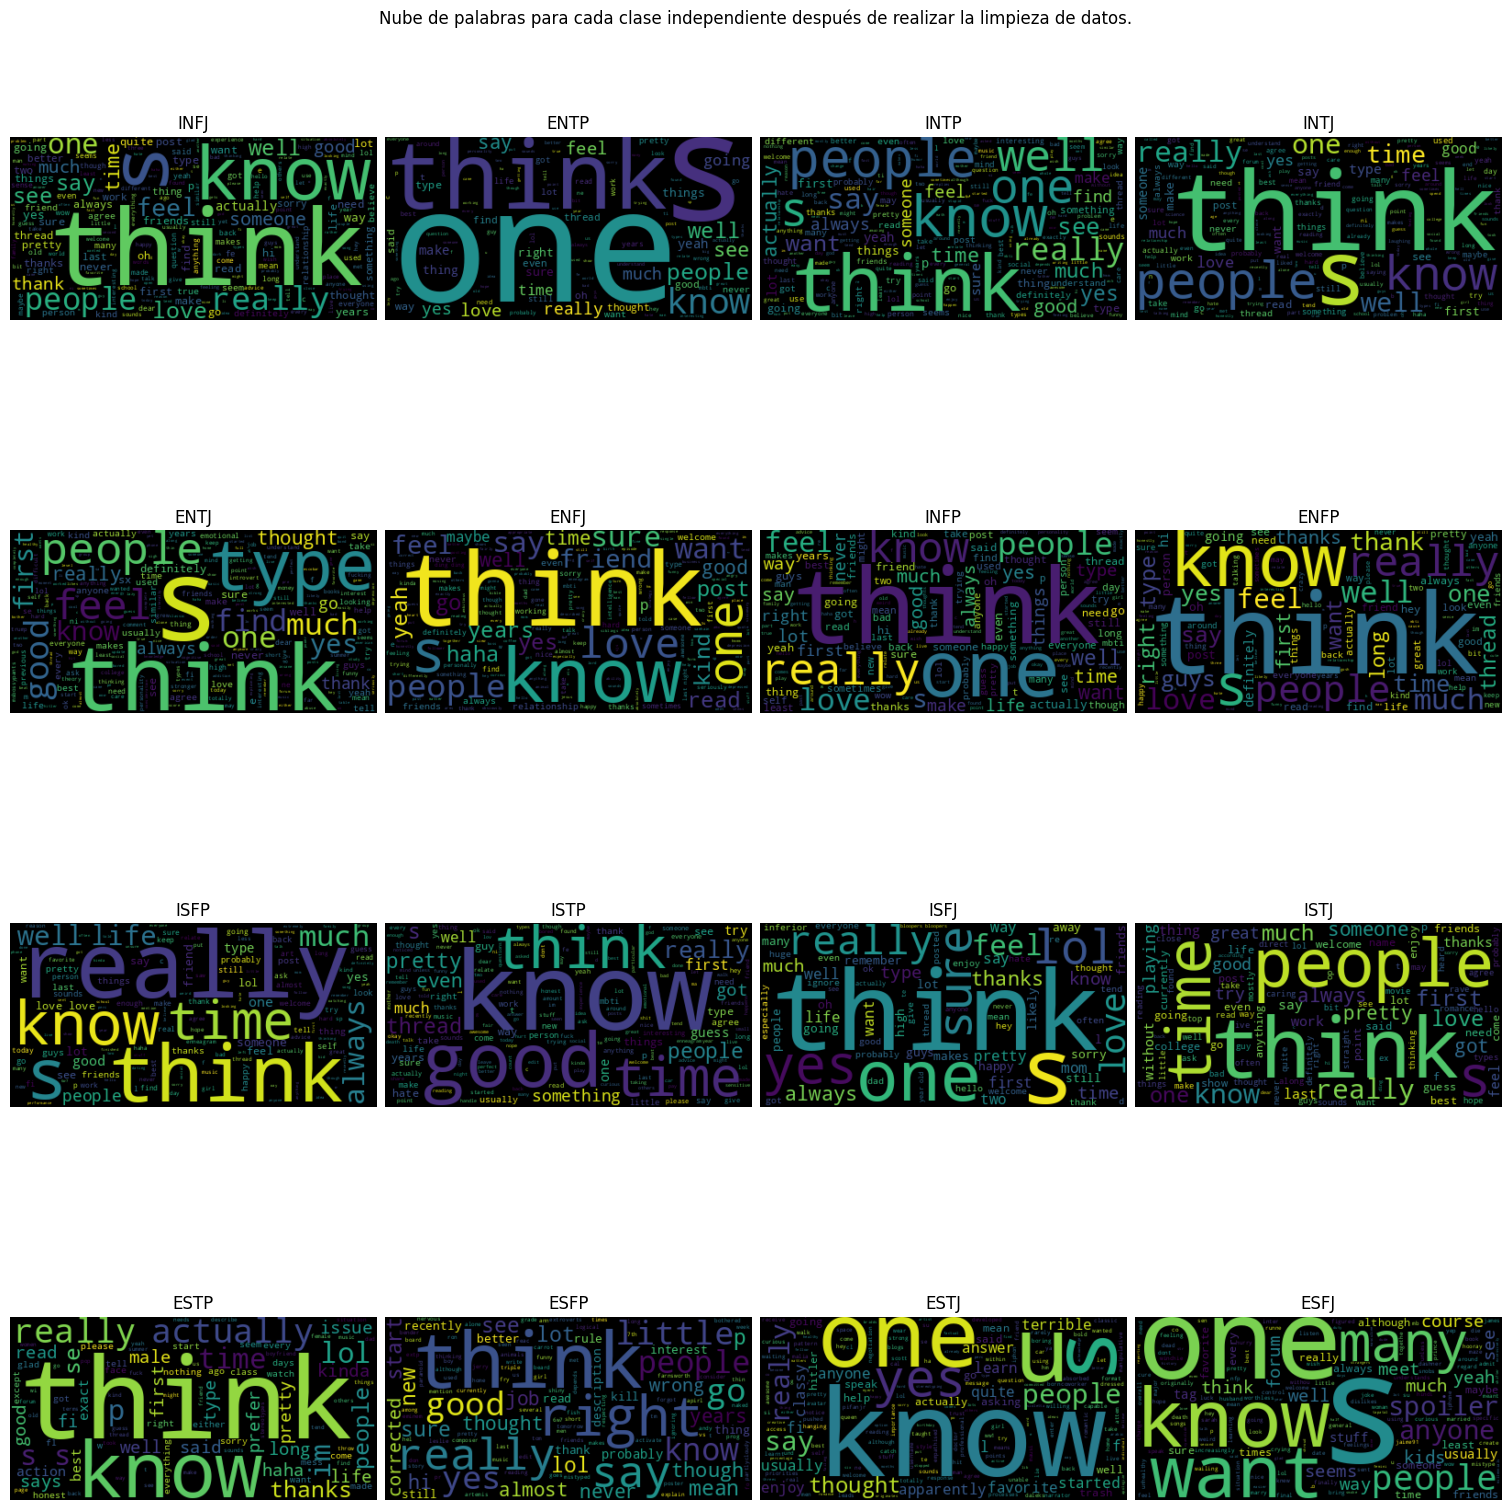

In [ ]:
num_classes = len(df_clean['type'].unique())
num_rows = num_classes // 4 + (1 if num_classes % 4 != 0 else 0)
num_cols = min(4, num_classes)

fig, axs = plt.subplots(num_rows, num_cols, figsize=(15, 4 * num_rows), constrained_layout=True)
plt.suptitle("Nube de palabras para cada clase independiente después de realizar la limpieza de datos.")
if not isinstance(axs, np.ndarray):
    axs = np.array([axs])

for i, ax in zip(df_clean['type'].unique(), axs.flat):
    df_4 = df_clean[df_clean['type'] == i]
    wordcloud = WordCloud(max_words=1628, relative_scaling=1, normalize_plurals=False).generate(df_4['posts'].to_string())
    ax.imshow(wordcloud, interpolation='bilinear')
    ax.set_title(i)
    ax.axis("off")

for ax in axs.flat[num_classes:]:
    ax.set_visible(False)

plt.show()

## Preprocesamos los datos

In [ ]:
mbti_df["posts"] = mbti_df["posts"].str.lower()

In [ ]:
for i in range(len(mbti_df)):
  post_temp=mbti_df._get_value(i, 'posts')
  pattern = re.compile(r'https?://[a-zA-Z0-9./-]*/[a-zA-Z0-9?=_.]*[_0-9.a-zA-Z/-]*')
  post_temp= re.sub(pattern, ' ', post_temp)
  mbti_df._set_value(i, 'posts',post_temp)

In [ ]:
for i in range(len(mbti_df)):
  post_temp=mbti_df._get_value(i, 'posts')
  pattern = re.compile(r'[0-9]')
  post_temp= re.sub(pattern, ' ', post_temp)
  pattern = re.compile('\W+')
  post_temp= re.sub(pattern, ' ', post_temp)
  pattern = re.compile(r'[_+]')
  post_temp= re.sub(pattern, ' ', post_temp)
  mbti_df._set_value(i, 'posts',post_temp)

In [ ]:
for i in range(len(mbti_df)):
  post_temp=mbti_df._get_value(i, 'posts')
  pattern = re.compile('\s+')
  post_temp= re.sub(pattern, ' ', post_temp)
  mbti_df._set_value(i, 'posts', post_temp)

In [ ]:
from nltk.corpus import stopwords
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [ ]:
remove_words = stopwords.words("english")
for i in range(mbti_df.shape[0]):
  post_temp=mbti_df._get_value(i, 'posts')
  post_temp=" ".join([w for w in post_temp.split(' ') if w not in remove_words])
  mbti_df._set_value(i, 'posts', post_temp)

In [ ]:
from nltk.stem import WordNetLemmatizer
lemmatizer = WordNetLemmatizer()
nltk.download('wordnet')

[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

In [ ]:
for i in range(mbti_df.shape[0]):
  post_temp=mbti_df._get_value(i, 'posts')
  post_temp=" ".join([lemmatizer.lemmatize(w) for w in post_temp.split(' ')])
  mbti_df._set_value(i, 'posts', post_temp)

In [ ]:
print(mbti_df)

      type                                              posts
0     INFJ   moment sportscenter top ten play prank life c...
1     ENTP  finding lack post alarming sex boring position...
2     INTP  good one course say know blessing curse absolu...
3     INTJ  dear enjoyed conversation day esoteric gabbing...
4     ENTJ  fired another silly misconception approaching ...
...    ...                                                ...
8670  ISFP  always think cat fi doms reason website become...
8671  ENFP  thread already exists someplace else heck dele...
8672  INTP  many question thing would take purple pill pic...
8673  INFP  conflicted right come wanting child honestly m...
8674  INFP  long since personalitycafe although seem chang...

[8675 rows x 2 columns]


In [ ]:
from sklearn.model_selection import train_test_split
train_data,test_data=train_test_split(mbti_df,test_size=0.2,random_state=42,stratify=mbti_df.type)

In [ ]:
print(test_data)

      type                                              posts
7814  INFP  macona depends big family extroverted people e...
2233  ENFJ  sveltihel brilliant episode regeneration sickn...
7261  INFJ  heylena lol compliment accepted thank jeesh fo...
7794  INFJ   pac right rocket coffin like packed warhead r...
2950  INTJ  title thread misleading mention world dominati...
...    ...                                                ...
2006  INTJ  one sentence restrictive accurately portray de...
7137  ISTJ  wanted like odd hybrid dr james wilson house h...
6091  ENTP  took cognitive process test got cognitive proc...
2997  INFJ  get caught fantacy relationship better forget ...
5458  ENTJ  doll love movie listed make think tritype one ...

[1735 rows x 2 columns]


In [ ]:
vectorizer=TfidfVectorizer( max_features=5000,stop_words='english')
vectorizer.fit(train_data.posts)
train_post=vectorizer.transform(train_data.posts).toarray()
test_post=vectorizer.transform(test_data.posts).toarray()

In [ ]:
from sklearn.preprocessing import LabelEncoder
target_encoder=LabelEncoder()
train_target=target_encoder.fit_transform(train_data.type)
test_target=target_encoder.fit_transform(test_data.type)

##Training different models and testing their performance




###Gaussian Naive Bayes

In [ ]:
from sklearn.naive_bayes import GaussianNB

In [ ]:
model_gnb=GaussianNB()
model_gnb.fit(train_post,train_target)
pred_gnb=model_gnb.predict(test_post)

In [ ]:
pred_training_gnb=model_gnb.predict(train_post)

In [ ]:
print("El puntaje de precisión del entrenamiento para el modelo entrenado con el Clasificador de Naive Bayes Gaussiano es:",accuracy_score(train_target,pred_training_gnb))

El puntaje de precisión del entrenamiento para el modelo entrenado con el Clasificador de Naive Bayes Gaussiano es: 0.6678674351585014


In [ ]:
print("El puntaje de precisión de prueba para el modelo entrenado con el Clasificador de Naive Bayes Gaussiano es:",accuracy_score(test_target,pred_gnb))

El puntaje de precisión de prueba para el modelo entrenado con el Clasificador de Naive Bayes Gaussiano es: 0.2426512968299712


In [ ]:
from sklearn.metrics import classification_report
personality_types=target_encoder.inverse_transform([i for i in range(16)])
print('Informe de clasificación de prueba del Clasificador de Naive Bayes Gaussiano.\n',classification_report(test_target,model_gnb.predict(test_post),target_names=personality_types))

Informe de clasificación de prueba del Clasificador de Naive Bayes Gaussiano.
               precision    recall  f1-score   support

        ENFJ       0.09      0.05      0.07        38
        ENFP       0.19      0.21      0.20       135
        ENTJ       0.01      0.02      0.02        46
        ENTP       0.20      0.20      0.20       137
        ESFJ       0.00      0.00      0.00         9
        ESFP       0.00      0.00      0.00        10
        ESTJ       0.00      0.00      0.00         8
        ESTP       0.00      0.00      0.00        18
        INFJ       0.34      0.29      0.31       294
        INFP       0.40      0.32      0.36       366
        INTJ       0.24      0.25      0.25       218
        INTP       0.33      0.30      0.31       261
        ISFJ       0.00      0.00      0.00        33
        ISFP       0.06      0.11      0.08        54
        ISTJ       0.17      0.12      0.14        41
        ISTP       0.09      0.28      0.13        67

 

/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


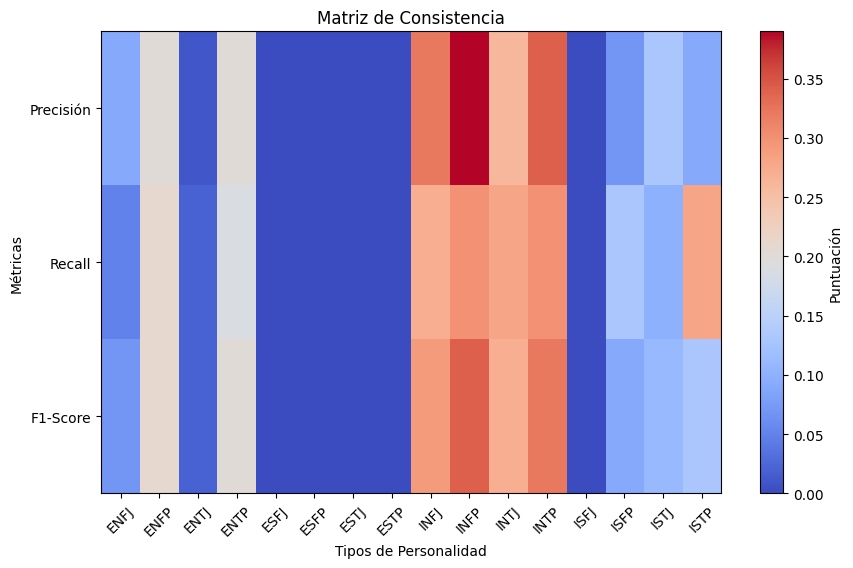

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Define los valores de precisión, recall y f1-score
precision = [0.09, 0.20, 0.01, 0.20, 0.00, 0.00, 0.00, 0.00, 0.32, 0.39, 0.26, 0.34, 0.00, 0.07, 0.13, 0.09]
recall = [0.05, 0.21, 0.02, 0.19, 0.00, 0.00, 0.00, 0.00, 0.27, 0.30, 0.28, 0.30, 0.00, 0.13, 0.10, 0.28]
f1_score = [0.07, 0.21, 0.02, 0.20, 0.00, 0.00, 0.00, 0.00, 0.29, 0.34, 0.27, 0.32, 0.00, 0.09, 0.11, 0.13]

# Crea la matriz de consistencia
conf_matrix = np.array([precision, recall, f1_score])

# Define los tipos de personalidad
personality_types = ['ENFJ', 'ENFP', 'ENTJ', 'ENTP', 'ESFJ', 'ESFP', 'ESTJ', 'ESTP',
                     'INFJ', 'INFP', 'INTJ', 'INTP', 'ISFJ', 'ISFP', 'ISTJ', 'ISTP']

# Plotea la matriz de consistencia
plt.figure(figsize=(10, 6))
plt.imshow(conf_matrix, cmap='coolwarm', aspect='auto')
plt.xticks(range(len(personality_types)), personality_types, rotation=45)
plt.yticks(range(3), ['Precisión', 'Recall', 'F1-Score'])
plt.xlabel('Tipos de Personalidad')
plt.ylabel('Métricas')
plt.title('Matriz de Consistencia')
plt.colorbar(label='Puntuación')
plt.show()


###Multinomial Naive Bayes

In [ ]:
from sklearn.naive_bayes import MultinomialNB

In [ ]:
model_mnb=MultinomialNB()
model_mnb.fit(train_post,train_target)
pred_mnb=model_mnb.predict(test_post)

In [ ]:
pred_training_mnb=model_mnb.predict(train_post)

In [ ]:
print("El puntaje de precisión de entrenamiento para el modelo entrenado con el Clasificador de Naive Bayes Multinomial es:",accuracy_score(train_target,pred_training_mnb))

El puntaje de precisión de entrenamiento para el modelo entrenado con el Clasificador de Naive Bayes Multinomial es: 0.39106628242074926


In [ ]:
print("El puntaje de precisión de prueba para el modelo entrenado con el Clasificador de Naive Bayes Multinomial es::",accuracy_score(test_target,pred_mnb))

El puntaje de precisión de prueba para el modelo entrenado con el Clasificador de Naive Bayes Multinomial es:: 0.30028818443804034


In [ ]:
from sklearn.metrics import classification_report
personality_types=target_encoder.inverse_transform([i for i in range(16)])
print('Informe de clasificación de prueba del Clasificador de Naive Bayes Multinomial. \n',classification_report(test_target,model_mnb.predict(test_post),target_names=personality_types))

Informe de clasificación de prueba del Clasificador de Naive Bayes Multinomial. 
               precision    recall  f1-score   support

        ENFJ       0.00      0.00      0.00        38
        ENFP       0.00      0.00      0.00       135
        ENTJ       0.00      0.00      0.00        46
        ENTP       0.00      0.00      0.00       137
        ESFJ       0.00      0.00      0.00         9
        ESFP       0.00      0.00      0.00        10
        ESTJ       0.00      0.00      0.00         8
        ESTP       0.00      0.00      0.00        18
        INFJ       0.27      0.28      0.28       294
        INFP       0.28      0.86      0.42       366
        INTJ       0.46      0.11      0.18       218
        INTP       0.42      0.39      0.40       261
        ISFJ       0.00      0.00      0.00        33
        ISFP       0.00      0.00      0.00        54
        ISTJ       0.00      0.00      0.00        41
        ISTP       0.00      0.00      0.00        67

/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


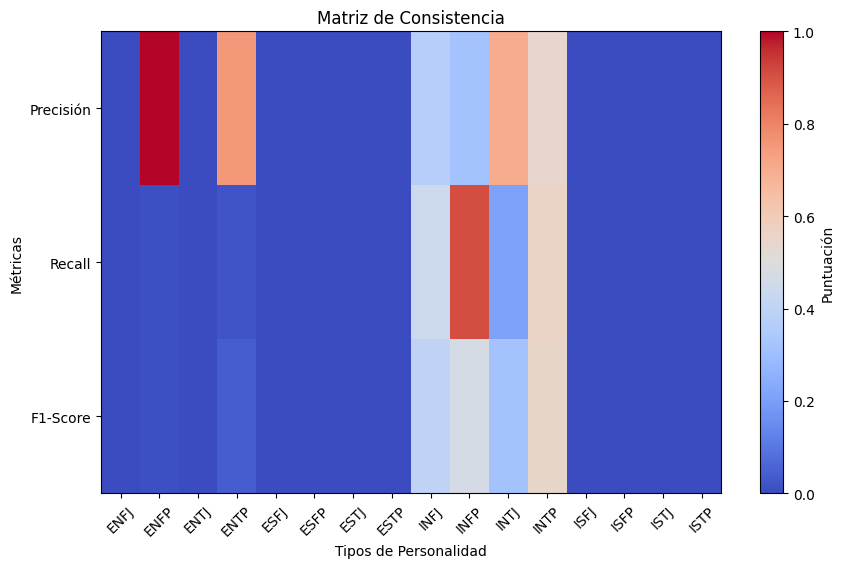

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Define los valores de precisión, recall y f1-score
precision = [0.00, 1.00, 0.00, 0.75, 0.00, 0.00, 0.00, 0.00, 0.37, 0.32, 0.70, 0.54, 0.00, 0.00, 0.00, 0.00]
recall = [0.00, 0.01, 0.00, 0.02, 0.00, 0.00, 0.00, 0.00, 0.44, 0.91, 0.21, 0.56, 0.00, 0.00, 0.00, 0.00]
f1_score = [0.00, 0.01, 0.00, 0.04, 0.00, 0.00, 0.00, 0.00, 0.40, 0.47, 0.32, 0.55, 0.00, 0.00, 0.00, 0.00]

# Crea la matriz de consistencia
conf_matrix = np.array([precision, recall, f1_score])

# Define los tipos de personalidad
personality_types = ['ENFJ', 'ENFP', 'ENTJ', 'ENTP', 'ESFJ', 'ESFP', 'ESTJ', 'ESTP',
                     'INFJ', 'INFP', 'INTJ', 'INTP', 'ISFJ', 'ISFP', 'ISTJ', 'ISTP']

# Plotea la matriz de consistencia
plt.figure(figsize=(10, 6))
plt.imshow(conf_matrix, cmap='coolwarm', aspect='auto')
plt.xticks(range(len(personality_types)), personality_types, rotation=45)
plt.yticks(range(3), ['Precisión', 'Recall', 'F1-Score'])
plt.xlabel('Tipos de Personalidad')
plt.ylabel('Métricas')
plt.title('Matriz de Consistencia')
plt.colorbar(label='Puntuación')
plt.show()

###Random Forest Classifier

In [ ]:
from sklearn.ensemble import RandomForestClassifier

In [ ]:
model_rfc=RandomForestClassifier()
model_rfc.fit(train_post,train_target)
pred_rfc=model_rfc.predict(test_post)

In [ ]:
pred_training_rfc=model_rfc.predict(train_post)

In [ ]:
print("El puntaje de precisión de entrenamiento para el modelo entrenado con Random Forest es:",accuracy_score(train_target,pred_training_rfc))

El puntaje de precisión de entrenamiento para el modelo entrenado con Random Forest es: 1.0


In [ ]:
print("El puntaje de precisión de prueba para el modelo entrenado con RF es:",accuracy_score(test_target,pred_rfc))

El puntaje de precisión de prueba para el modelo entrenado con RF es: 0.276657060518732


In [ ]:
from sklearn.metrics import classification_report
personality_types=target_encoder.inverse_transform([i for i in range(16)])
print('Informe de clasificación de prueba del Random Forest Classifier\n',classification_report(test_target,model_rfc.predict(test_post),target_names=personality_types))

Informe de clasificación de prueba del Random Forest Classifier
               precision    recall  f1-score   support

        ENFJ       0.00      0.00      0.00        38
        ENFP       0.00      0.00      0.00       135
        ENTJ       0.00      0.00      0.00        46
        ENTP       0.40      0.01      0.03       137
        ESFJ       0.00      0.00      0.00         9
        ESFP       0.00      0.00      0.00        10
        ESTJ       0.00      0.00      0.00         8
        ESTP       0.00      0.00      0.00        18
        INFJ       0.23      0.31      0.26       294
        INFP       0.29      0.75      0.42       366
        INTJ       0.30      0.16      0.21       218
        INTP       0.29      0.30      0.30       261
        ISFJ       0.00      0.00      0.00        33
        ISFP       0.00      0.00      0.00        54
        ISTJ       0.00      0.00      0.00        41
        ISTP       0.00      0.00      0.00        67

    accuracy   

/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


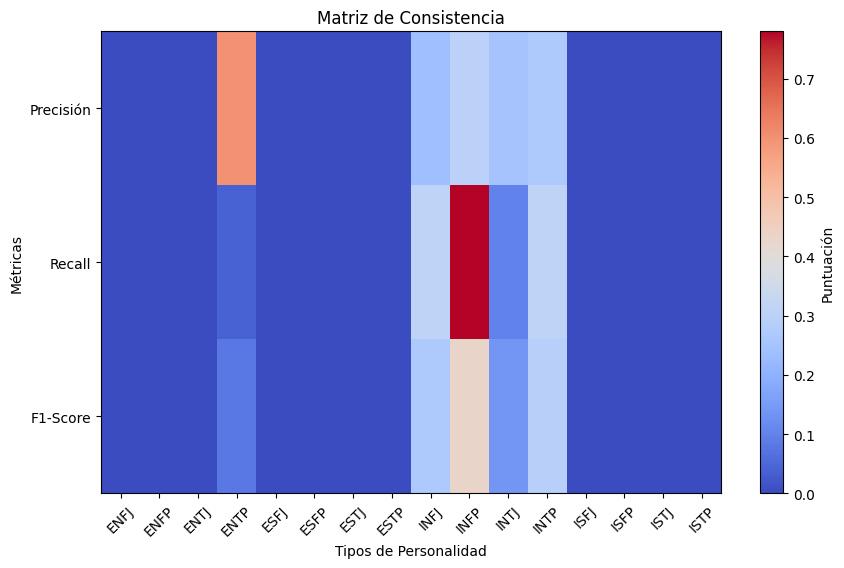

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Define los valores de precisión, recall y f1-score
precision = [0.00, 0.00, 0.00, 0.60, 0.00, 0.00, 0.00, 0.00, 0.24, 0.30, 0.25, 0.27, 0.00, 0.00, 0.00, 0.00]
recall = [0.00, 0.00, 0.00, 0.04, 0.00, 0.00, 0.00, 0.00, 0.31, 0.78, 0.10, 0.31, 0.00, 0.00, 0.00, 0.00]
f1_score = [0.00, 0.00, 0.00, 0.08, 0.00, 0.00, 0.00, 0.00, 0.27, 0.43, 0.14, 0.29, 0.00, 0.00, 0.00, 0.00]

# Crea la matriz de consistencia
conf_matrix = np.array([precision, recall, f1_score])

# Define los tipos de personalidad
personality_types = ['ENFJ', 'ENFP', 'ENTJ', 'ENTP', 'ESFJ', 'ESFP', 'ESTJ', 'ESTP',
                     'INFJ', 'INFP', 'INTJ', 'INTP', 'ISFJ', 'ISFP', 'ISTJ', 'ISTP']

# Plotea la matriz de consistencia
plt.figure(figsize=(10, 6))
plt.imshow(conf_matrix, cmap='coolwarm', aspect='auto')
plt.xticks(range(len(personality_types)), personality_types, rotation=45)
plt.yticks(range(3), ['Precisión', 'Recall', 'F1-Score'])
plt.xlabel('Tipos de Personalidad')
plt.ylabel('Métricas')
plt.title('Matriz de Consistencia')
plt.colorbar(label='Puntuación')
plt.show()

### Clasificador XGBoost

In [ ]:
from xgboost import XGBClassifier
model_xgb=XGBClassifier()
model_xgb.fit(train_post,train_target)
pred_xgb=model_xgb.predict(test_post)

In [ ]:
pred_training_xgb=model_xgb.predict(train_post)

In [ ]:
print("El puntaje de precisión de entrenamiento para el modelo entrenado con el Clasificador XGBoost es:",accuracy_score(train_target,pred_training_xgb))

El puntaje de precisión de entrenamiento para el modelo entrenado con el Clasificador XGBoost es: 0.9997118155619596


In [ ]:
print("El puntaje de precisión de prueba para el modelo entrenado con el clasificador XGBoost es:",accuracy_score(test_target,pred_xgb))

El puntaje de precisión de prueba para el modelo entrenado con el clasificador XGBoost es: 0.3389048991354467


In [ ]:
from sklearn.metrics import classification_report
personality_types=target_encoder.inverse_transform([i for i in range(16)])
print('Informe de clasificación de prueba del clasificador XGBoost.\n',classification_report(test_target,model_xgb.predict(test_post),target_names=personality_types))

Informe de clasificación de prueba del clasificador XGBoost.
               precision    recall  f1-score   support

        ENFJ       1.00      0.03      0.05        38
        ENFP       0.35      0.12      0.18       135
        ENTJ       0.00      0.00      0.00        46
        ENTP       0.33      0.20      0.25       137
        ESFJ       0.00      0.00      0.00         9
        ESFP       0.00      0.00      0.00        10
        ESTJ       0.00      0.00      0.00         8
        ESTP       0.00      0.00      0.00        18
        INFJ       0.31      0.43      0.36       294
        INFP       0.36      0.61      0.45       366
        INTJ       0.30      0.31      0.31       218
        INTP       0.36      0.45      0.40       261
        ISFJ       0.00      0.00      0.00        33
        ISFP       1.00      0.04      0.07        54
        ISTJ       0.33      0.02      0.05        41
        ISTP       0.57      0.06      0.11        67

    accuracy      

/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


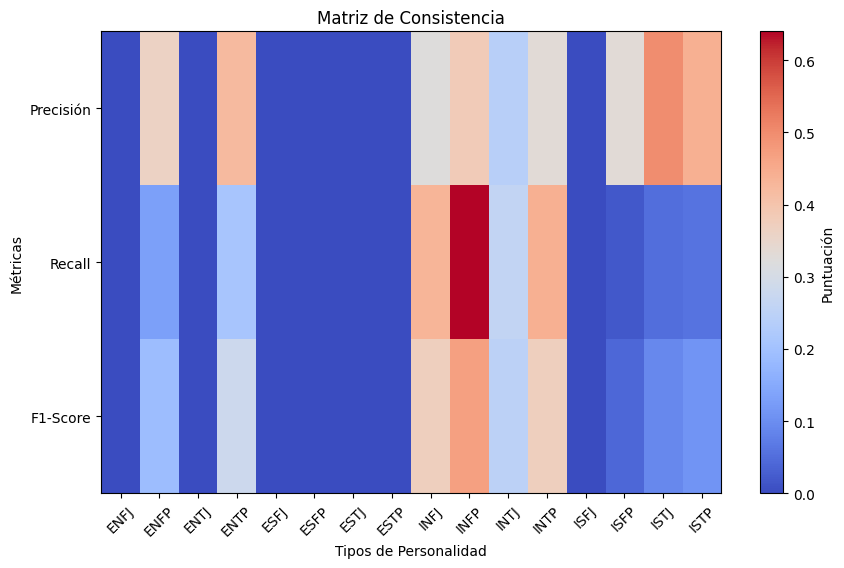

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Define los valores de precisión, recall y f1-score
precision = [0.00, 0.36, 0.00, 0.42, 0.00, 0.00, 0.00, 0.00, 0.32, 0.38, 0.24, 0.33, 0.00, 0.33, 0.50, 0.44]
recall = [0.00, 0.13, 0.00, 0.21, 0.00, 0.00, 0.00, 0.00, 0.43, 0.64, 0.26, 0.44, 0.00, 0.02, 0.05, 0.06]
f1_score = [0.00, 0.19, 0.00, 0.28, 0.00, 0.00, 0.00, 0.00, 0.37, 0.47, 0.25, 0.37, 0.00, 0.04, 0.09, 0.11]

# Crea la matriz de consistencia
conf_matrix = np.array([precision, recall, f1_score])

# Define los tipos de personalidad
personality_types = ['ENFJ', 'ENFP', 'ENTJ', 'ENTP', 'ESFJ', 'ESFP', 'ESTJ', 'ESTP',
                     'INFJ', 'INFP', 'INTJ', 'INTP', 'ISFJ', 'ISFP', 'ISTJ', 'ISTP']

# Plotea la matriz de consistencia
plt.figure(figsize=(10, 6))
plt.imshow(conf_matrix, cmap='coolwarm', aspect='auto')
plt.xticks(range(len(personality_types)), personality_types, rotation=45)
plt.yticks(range(3), ['Precisión', 'Recall', 'F1-Score'])
plt.xlabel('Tipos de Personalidad')
plt.ylabel('Métricas')
plt.title('Matriz de Consistencia')
plt.colorbar(label='Puntuación')
plt.show()

###LightGBM Classifier

In [77]:
from lightgbm import LGBMClassifier as lgb
model_lgb = lgb()
model_lgb.fit(train_post,train_target)
pred_lgb=model_lgb.predict(test_post)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.572450 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 465312
[LightGBM] [Info] Number of data points in the train set: 6940, number of used features: 4999
[LightGBM] [Info] Start training from score -3.821177
[LightGBM] [Info] Start training from score -2.553488
[LightGBM] [Info] Start training from score -3.624701
[LightGBM] [Info] Start training from score -2.538782
[LightGBM] [Info] Start training from score -5.348549
[LightGBM] [Info] Start training from score -5.207471
[LightGBM] [Info] Start training from score -5.411070
[LightGBM] [Info] Start training from score -4.582377
[LightGBM] [Info] Start training from score -1.775183
[LightGBM] [Info] Start training from score -1.554764
[LightGBM] [Info] Start training from score -2.073121
[LightGBM] [Info] Start training from score -1.895

In [ ]:
pred_training_lgb=model_lgb.predict(train_post)

In [ ]:
print("El puntaje de precisión de entrenamiento para el modelo entrenado con el clasificador LightGBM es:",accuracy_score(train_target,pred_training_lgb))

El puntaje de precisión de entrenamiento para el modelo entrenado con el clasificador LightGBM es: 0.9998559077809799


In [ ]:
print("El puntaje de precisión de prueba para el modelo entrenado con el clasificador LightGBM es:",accuracy_score(test_target,pred_lgb))

El puntaje de precisión de prueba para el modelo entrenado con el clasificador LightGBM es: 0.3585014409221902


In [ ]:
from sklearn.metrics import classification_report
personality_types=target_encoder.inverse_transform([i for i in range(16)])
print('Informe de clasificación de prueba del clasificador LightGBM.\n',classification_report(test_target,model_lgb.predict(test_post),target_names=personality_types))

Test classification report of LightGBM Classifier
               precision    recall  f1-score   support

        ENFJ       0.71      0.39      0.51        38
        ENFP       0.72      0.65      0.68       135
        ENTJ       0.74      0.43      0.55        46
        ENTP       0.59      0.58      0.59       137
        ESFJ       1.00      0.11      0.20         9
        ESFP       0.00      0.00      0.00        10
        ESTJ       0.00      0.00      0.00         8
        ESTP       0.56      0.28      0.37        18
        INFJ       0.68      0.75      0.71       294
        INFP       0.66      0.81      0.73       366
        INTJ       0.66      0.67      0.67       218
        INTP       0.70      0.77      0.73       261
        ISFJ       0.67      0.42      0.52        33
        ISFP       0.79      0.50      0.61        54
        ISTJ       0.68      0.37      0.48        41
        ISTP       0.68      0.57      0.62        67

    accuracy                 

/usr/local/lib/python3.7/dist-packages/sklearn/metrics/_classification.py:1318: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.7/dist-packages/sklearn/metrics/_classification.py:1318: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.7/dist-packages/sklearn/metrics/_classification.py:1318: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


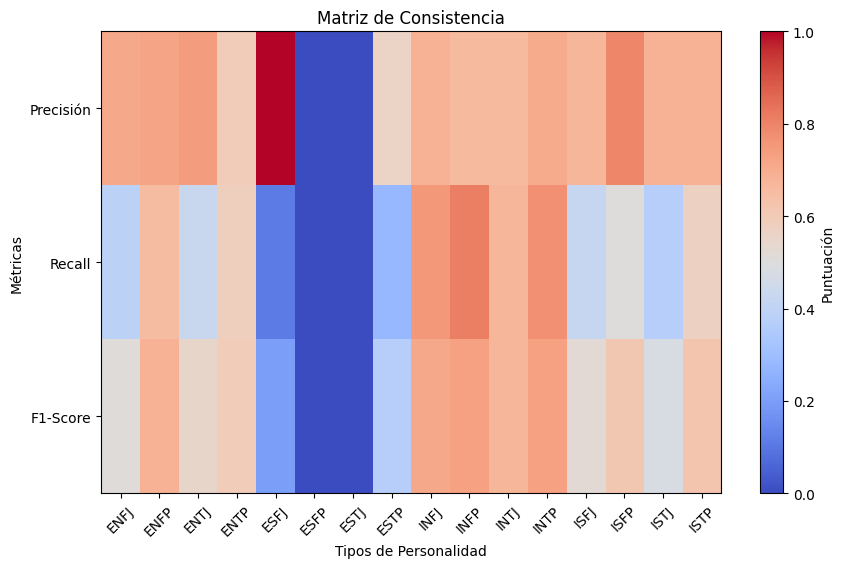

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Define los valores de precisión, recall y f1-score
precision = [0.71, 0.72, 0.74, 0.59, 1.00, 0.00, 0.00, 0.56, 0.68, 0.66, 0.66, 0.70, 0.67, 0.79, 0.68, 0.68]
recall = [0.39, 0.65, 0.43, 0.58, 0.11, 0.00, 0.00, 0.28, 0.75, 0.81, 0.67, 0.77, 0.42, 0.50, 0.37, 0.57]
f1_score = [0.51, 0.68, 0.55, 0.59, 0.20, 0.00, 0.00, 0.37, 0.71, 0.73, 0.67, 0.73, 0.52, 0.61, 0.48, 0.62]

# Crea la matriz de consistencia
conf_matrix = np.array([precision, recall, f1_score])

# Define los tipos de personalidad
personality_types = ['ENFJ', 'ENFP', 'ENTJ', 'ENTP', 'ESFJ', 'ESFP', 'ESTJ', 'ESTP',
                     'INFJ', 'INFP', 'INTJ', 'INTP', 'ISFJ', 'ISFP', 'ISTJ', 'ISTP']

# Plotea la matriz de consistencia
plt.figure(figsize=(10, 6))
plt.imshow(conf_matrix, cmap='coolwarm', aspect='auto')
plt.xticks(range(len(personality_types)), personality_types, rotation=45)
plt.yticks(range(3), ['Precisión', 'Recall', 'F1-Score'])
plt.xlabel('Tipos de Personalidad')
plt.ylabel('Métricas')
plt.title('Matriz de Consistencia')
plt.colorbar(label='Puntuación')
plt.show()

###Support Vector Classifier

In [ ]:
from sklearn.svm import SVC

In [ ]:
model_svc=SVC()
model_svc.fit(train_post,train_target)
pred_svc=model_svc.predict(test_post)

In [ ]:
pred_training_svc=model_svc.predict(train_post)

In [ ]:
print("El puntaje de precisión de entrenamiento para el modelo entrenado con el clasificador de Soporte es:",accuracy_score(train_target,pred_training_svc))

El puntaje de precisión de entrenamiento para el modelo entrenado con el clasificador de Soporte es: 0.8744956772334294


In [ ]:
print("El puntaje de precisión de prueba para el modelo entrenado con el clasificador de vectores de soporte es:",accuracy_score(test_target,pred_svc))

El puntaje de precisión de prueba para el modelo entrenado con el clasificador de vectores de soporte es: 0.3659942363112392


In [ ]:
from sklearn.metrics import classification_report
personality_types=target_encoder.inverse_transform([i for i in range(16)])
print('Informe de clasificación de prueba de la Máquina de Vectores de Soporte.\n',classification_report(test_target,model_svc.predict(test_post),target_names=personality_types))

Informe de clasificación de prueba de la Máquina de Vectores de Soporte.
               precision    recall  f1-score   support

        ENFJ       0.00      0.00      0.00        38
        ENFP       0.44      0.09      0.15       135
        ENTJ       0.00      0.00      0.00        46
        ENTP       0.33      0.06      0.10       137
        ESFJ       0.00      0.00      0.00         9
        ESFP       0.00      0.00      0.00        10
        ESTJ       0.00      0.00      0.00         8
        ESTP       0.00      0.00      0.00        18
        INFJ       0.33      0.37      0.35       294
        INFP       0.37      0.77      0.50       366
        INTJ       0.36      0.32      0.34       218
        INTP       0.38      0.59      0.46       261
        ISFJ       0.00      0.00      0.00        33
        ISFP       0.00      0.00      0.00        54
        ISTJ       0.00      0.00      0.00        41
        ISTP       1.00      0.01      0.03        67

    ac

/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


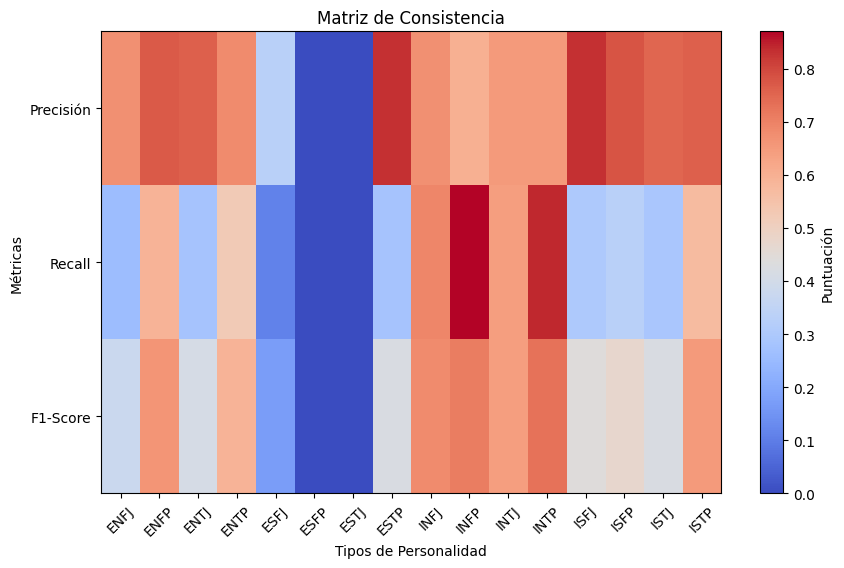

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Define los valores de precisión, recall y f1-score
precision = [0.67, 0.77, 0.76, 0.68, 0.33, 0.00, 0.00, 0.83, 0.67, 0.60, 0.65, 0.65, 0.83, 0.78, 0.75, 0.76]
recall = [0.26, 0.59, 0.28, 0.52, 0.11, 0.00, 0.00, 0.28, 0.69, 0.87, 0.64, 0.84, 0.30, 0.33, 0.29, 0.57]
f1_score = [0.38, 0.66, 0.41, 0.59, 0.17, 0.00, 0.00, 0.42, 0.68, 0.71, 0.64, 0.73, 0.44, 0.47, 0.42, 0.65]

# Crea la matriz de consistencia
conf_matrix = np.array([precision, recall, f1_score])

# Define los tipos de personalidad
personality_types = ['ENFJ', 'ENFP', 'ENTJ', 'ENTP', 'ESFJ', 'ESFP', 'ESTJ', 'ESTP',
                     'INFJ', 'INFP', 'INTJ', 'INTP', 'ISFJ', 'ISFP', 'ISTJ', 'ISTP']

# Plotea la matriz de consistencia
plt.figure(figsize=(10, 6))
plt.imshow(conf_matrix, cmap='coolwarm', aspect='auto')
plt.xticks(range(len(personality_types)), personality_types, rotation=45)
plt.yticks(range(3), ['Precisión', 'Recall', 'F1-Score'])
plt.xlabel('Tipos de Personalidad')
plt.ylabel('Métricas')
plt.title('Matriz de Consistencia')
plt.colorbar(label='Puntuación')
plt.show()

###Logistic Regression

In [ ]:
from sklearn.linear_model import LogisticRegression

In [ ]:
model_lr=LogisticRegression()
model_lr.fit(train_post,train_target)
pred_lr=model_lr.predict(test_post)

/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_logistic.py:458: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [ ]:
pred_training_lr=model_lr.predict(train_post)

In [ ]:
print("El puntaje de precisión de entrenamiento para el modelo entrenado con la Regresión Logística es:",accuracy_score(train_target,pred_training_lr))

El puntaje de precisión de entrenamiento para el modelo entrenado con la Regresión Logística es: 0.6402017291066282


In [ ]:
print("El puntaje de precisión de prueba para el modelo entrenado con Regresión Logística es:",accuracy_score(test_target,pred_lr))

El puntaje de precisión de prueba para el modelo entrenado con Regresión Logística es: 0.3861671469740634


In [ ]:
from sklearn.metrics import classification_report
personality_types=target_encoder.inverse_transform([i for i in range(16)])
print('Informe de clasificación de prueba de la Regresión Logística.\n',classification_report(test_target,model_lr.predict(test_post),target_names=personality_types))

Test classification report of Logistic Regression
               precision    recall  f1-score   support

        ENFJ       0.00      0.00      0.00        38
        ENFP       0.40      0.19      0.26       135
        ENTJ       0.00      0.00      0.00        46
        ENTP       0.36      0.15      0.21       137
        ESFJ       0.00      0.00      0.00         9
        ESFP       0.00      0.00      0.00        10
        ESTJ       0.00      0.00      0.00         8
        ESTP       0.00      0.00      0.00        18
        INFJ       0.37      0.44      0.40       294
        INFP       0.41      0.74      0.53       366
        INTJ       0.35      0.34      0.35       218
        INTP       0.39      0.56      0.46       261
        ISFJ       0.00      0.00      0.00        33
        ISFP       0.00      0.00      0.00        54
        ISTJ       1.00      0.02      0.05        41
        ISTP       0.40      0.03      0.06        67

    accuracy                 

/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


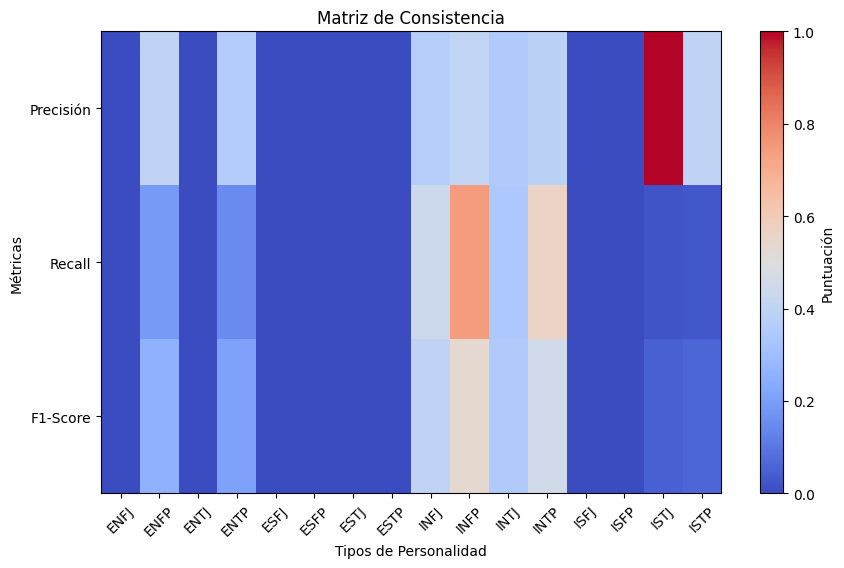

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Define los valores de precisión, recall y f1-score
precision = [0.00, 0.40, 0.00, 0.36, 0.00, 0.00, 0.00, 0.00, 0.37, 0.41, 0.35, 0.39, 0.00, 0.00, 1.00, 0.40]
recall = [0.00, 0.19, 0.00, 0.15, 0.00, 0.00, 0.00, 0.00, 0.44, 0.74, 0.34, 0.56, 0.00, 0.00, 0.02, 0.03]
f1_score = [0.00, 0.26, 0.00, 0.21, 0.00, 0.00, 0.00, 0.00, 0.40, 0.53, 0.35, 0.46, 0.00, 0.00, 0.05, 0.06]

# Crea la matriz de consistencia
conf_matrix = np.array([precision, recall, f1_score])

# Define los tipos de personalidad
personality_types = ['ENFJ', 'ENFP', 'ENTJ', 'ENTP', 'ESFJ', 'ESFP', 'ESTJ', 'ESTP',
                     'INFJ', 'INFP', 'INTJ', 'INTP', 'ISFJ', 'ISFP', 'ISTJ', 'ISTP']

# Plotea la matriz de consistencia
plt.figure(figsize=(10, 6))
plt.imshow(conf_matrix, cmap='coolwarm', aspect='auto')
plt.xticks(range(len(personality_types)), personality_types, rotation=45)
plt.yticks(range(3), ['Precisión', 'Recall', 'F1-Score'])
plt.xlabel('Tipos de Personalidad')
plt.ylabel('Métricas')
plt.title('Matriz de Consistencia')
plt.colorbar(label='Puntuación')
plt.show()

###Results

In [ ]:
result_df=pd.DataFrame({'Model':["Gaussian NB","Multinomial NB","Random Forest","XGBoost","LightGBM","SVM","Logistic Regresssion"],
                        'Accuracy':[accuracy_score(test_target,pred_gnb),accuracy_score(test_target,pred_mnb),accuracy_score(test_target,pred_rfc),accuracy_score(test_target,pred_xgb),accuracy_score(test_target,pred_lgb),accuracy_score(test_target,pred_svc),accuracy_score(test_target,pred_lr)]})

NameError: name 'pred_gnb' is not defined

In [ ]:
print(result_df.sort_values(by = 'Accuracy'))

                  Model  Accuracy
0           Gaussian NB  0.258790
1        Multinomial NB  0.380403
2         Random Forest  0.559654
6  Logistic Regresssion  0.650144
5                   SVM  0.653602
4              LightGBM  0.673775
3               XGBoost  0.675504
